In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv("hour.csv")

In [3]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [5]:
df.shape

(17379, 17)

In [6]:
df.duplicated().sum()

0

In [7]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


nuestro dataset cuenta con 17 columnas y 17379 filas. nuestras filas se dividen en texto, numeros enteros y numeros decimales. la columa Hr indica las horas totales de un dia. la hora minima que quivale a 0 es la hora de las 00:00. 

ocupare la columna hr para analizarla y saber cuantas biciletas se alquilan en 1 hora 


In [8]:
df["cnt"].describe()

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

hay 17379 registros validos de alquiler 
se alquilaros una media de 189 bicicletas por hora registrada 
std: los valores varias considerablemente entre hora 
20% de las horas registro 40 alquileres o menos 
50% (mediana)  registro 142 alquiileres o menos 
75% de las horas registro 281 alquielers o menos 
max el mayoro registro en 1 hora fue 997.. recomiendo investigar* 


In [9]:
Q1 = df["cnt"].quantile(0.25)
Q3 = df["cnt"].quantile(0.75)
IQR = Q3 - Q1
print("IQR:",IQR)

IQR: 241.0


Aca podemos conocer por medio de esta formula la aplitud de intervalo de nuestro boxplot 241 


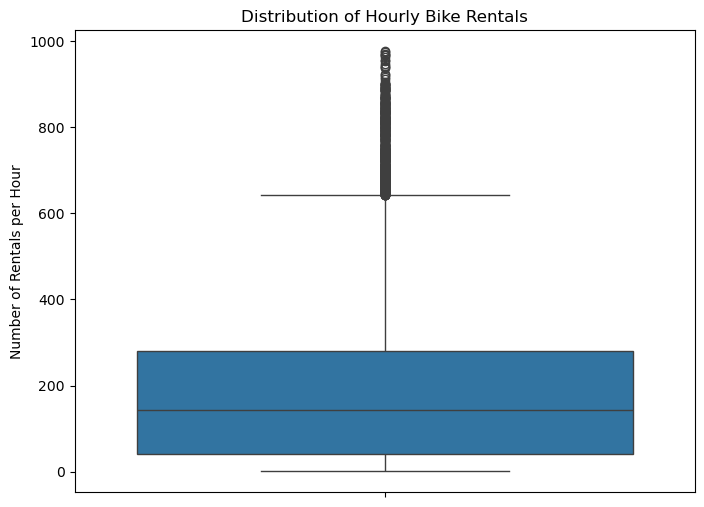

In [10]:
plt.figure(figsize = (8,6))
sns.boxplot(y = df["cnt"])
plt.title("Distribution of Hourly Bike Rentals")
plt.ylabel("Number of Rentals per Hour")
plt.show()


The boxplot suggests positive skewness, as the upper whisker is longer and outliers appear above it. I will create a histogram to examine the distribution of hourly bike rentals and identify the most frequent rental ranges.

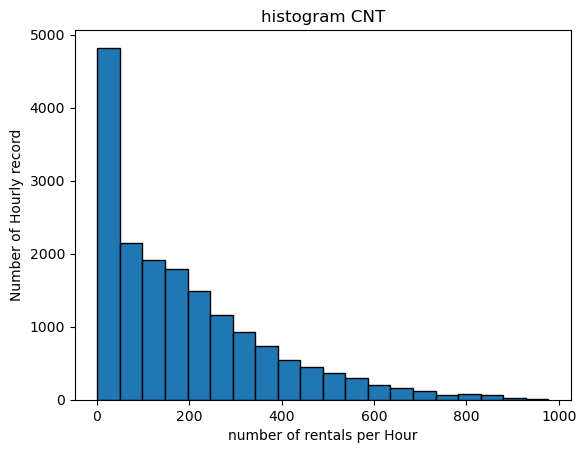

In [11]:
plt.hist(df["cnt"], bins=20, edgecolor="black")
plt.title("histogram CNT")
plt.xlabel("number of rentals per Hour")
plt.ylabel("Number of Hourly record")
plt.show() 

Of the 17,379 hourly records, approximately 4,800 show between 1 and 50 rentals per hour, based on a visual estimate from the histogram. Hours with fewer rentals are more frequent than hours with higher rental counts. This is consistent with what the boxplot suggested: the distribution has a tail extending towards higher values and is therefore positively skewed.

In [12]:
#como cambia el promedio de alquiler a lo largo del dia ? deberia trabajar con Hr y cnt cantidad total de alquiler y sacar el mean 
df.groupby("hr")["cnt"].mean()

hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64

During the period analysed, 17:00 had the highest average number of bike rentals, with approximately 461 rentals per recorded hour.

guardo los datos de mean para poder trabajar el grafico lineal que necesito. utilizo .index para hr y .values 
para los promedios de cnt 

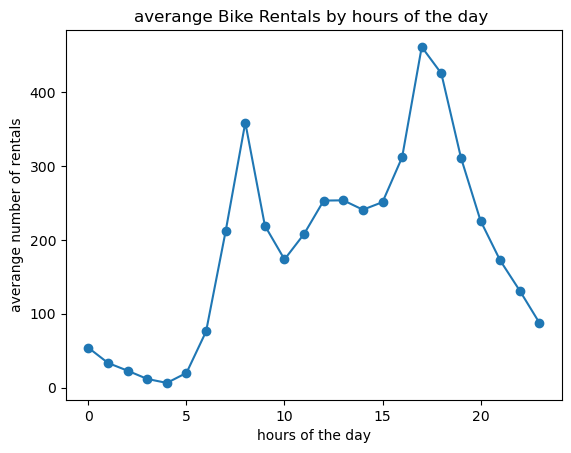

In [13]:
#definimos eje X he Y
mean_hr = df.groupby("hr")["cnt"].mean()
plt.plot(mean_hr.index, mean_hr.values, marker="o")

plt.title("averange Bike Rentals by hours of the day ")
plt.xlabel("hours of the day")
plt.ylabel("averange number of rentals")
plt.show()

como podemos observar el grafico nos muestras a que hora del dia se observa una renta mayor de bibicletas. podriamos interpretar que el promedio
comienza a aumentar a partir de las 5 de la mañana y alcanza un pico maximo a las 8 de la mañana esto puede deberse al desplazamiento matutino hacia el trabajo o al estudio. sin emabargo Pero el promedio mayor aparece a las 17:00 lo que puede deberse a al desplazamiento de regreso. 

ahora para comenzar a trabajar con binomial distribution me hare la primera pregunta: 
-en 20 dias comparables, ¿que probabilidad hay de que en almenos 12, 
se supere sierta cantidad de alquiler a las 17:00

para calcular binomial distribution, primero tengo que definir que probabilidad de alquileres consideraria un exito en mi proyecto.
    en este caso definire un exito ocurre cuando los alquileres a las 17:00 superan la media historica de las 17:00 del grupo selecionado 
    

In [14]:
#comienzo calculando la media del grupo (17:00) que voy a estudiar
selected = df[(df["hr"]==17) & (df["workingday"]==1)]
threshold = selected["cnt"].mean()
print("threshold:",threshold)
    


threshold: 525.2905811623247


In [15]:
#525 es el promedio de los dias laborales, esto quiere decir que si tengo 526 es exito y si tengo 525 alquileres o menos es fracaso 
#ahora guiandome por el ejercicio del profesor (distribution_sep2025) aparece que para sacar successfull debo hacer la siguiente formula

In [16]:
success= (selected["cnt"]>threshold).sum()
print("number of success:",success)

number of success: 267


In [ ]:
ahora que tenemos el numero de sucesos (267) se necesita calcular P = probabilidad estimada con registros hitoricos.

    p = valid selected observations above the  threshold / total valid selected observations 

In [24]:
total_records = selected["cnt"].count()
p_estimate = success / total_records
print("total records:",total_records)
print("estimated p:",p_estimate)

total records: 499
estimated p: 0.5350701402805611


p = 267 / 499 = 0,53507 

In [35]:
#importamos binom para poder calcular la probabilidad 
from scipy.stats import binom
n_trials = 20
p_success = p_estimate
probability = binom.sf(12 - 1, n_trials, p_success)

In [ ]:
# Binomial probability mass function (pmf)
binom_pmf = binom.pmf(k, n, p)    Formula ocupada para sacar binom desde (distribution_sep2025)

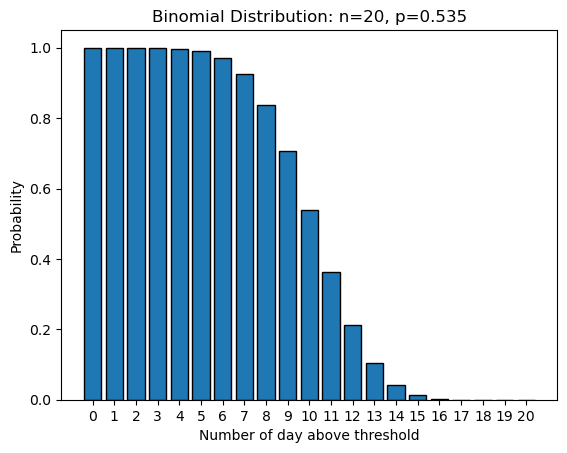

In [46]:
n = 20
p = p_estimate 
k_values = np.arange(n + 1)
probabilities = binom.sf(k_values, n, p)

plt.bar(k_values, probabilities, edgecolor='black')
plt.title('Binomial Distribution: n=20, p=0.535')
plt.xlabel("Number of day above threshold")
plt.ylabel('Probability')
plt.xticks(k_values)
plt.show()